# 01 Explore: Bangladesh RMG exports to the US and EU

Descriptive work before forecasting. Inputs come from `data/processed/`. Figures go to `outputs/figures/`, tables to `outputs/tables/`.

Caveats carried over from `outputs/QA_phase1.md`:
- US and EU series are importer-side values (CIF for the US, EU customs value converted from EUR). They are not Bangladesh FOB export figures.
- The mirror file (`rmg_market_annual.csv`) is used for shares only. 2024 and 2025 are incomplete there.
- 2026 is partial (US to July, EU to August).

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from statsmodels.tsa.seasonal import STL
from src.explore_utils import *
set_style()
d = load_long()
w = monthly_totals(d)
w.tail(3)

value_usd           value_usd_real2025          
market            EU        US                 EU        US
date                                                       
2026-06-01  1.582073  0.765711           1.532686  0.741808
2026-07-01  1.986186  0.659751           1.922767  0.638685
2026-08-01  1.742566       NaN           1.680272       NaN

## 1. Monthly imports, 2010 onward

Shaded: Rana Plaza (Apr 2013), COVID-19 (Mar-Jun 2020), political unrest (Jul-Aug 2024).

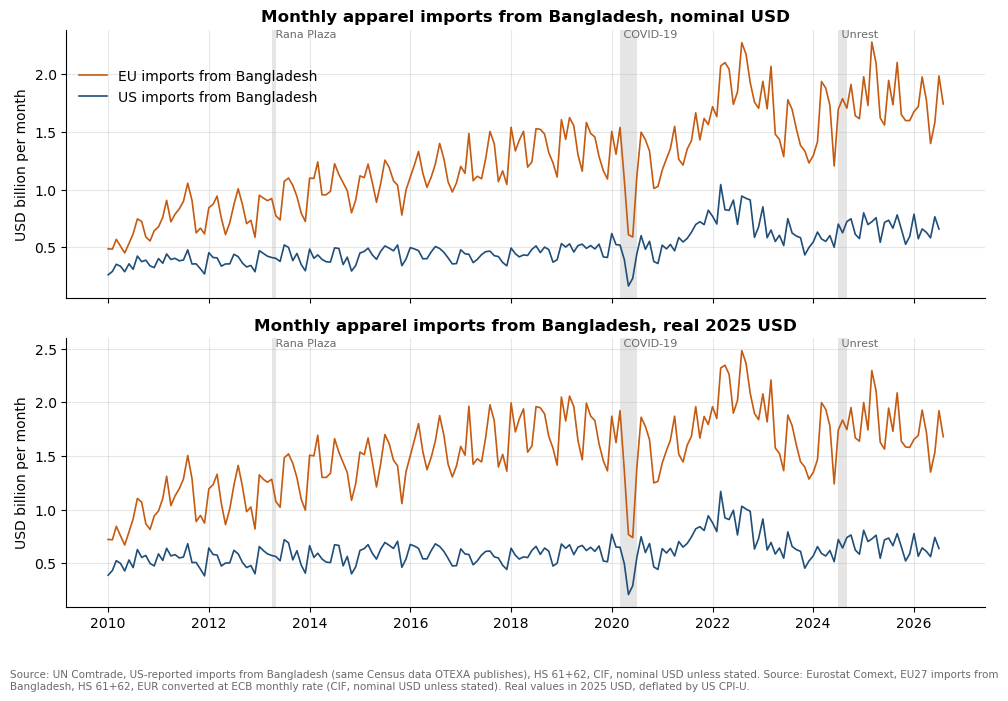

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, col, title in [(axes[0], 'value_usd', 'nominal USD'), (axes[1], 'value_usd_real2025', 'real 2025 USD')]:
    for m in ['EU', 'US']:
        ax.plot(w.index, w[(col, m)], color=COLORS[m], lw=1.2, label=f'{m} imports from Bangladesh')
    shade_events(ax)
    ax.set_title(f'Monthly apparel imports from Bangladesh, {title}')
    ax.set_ylabel('USD billion per month')
axes[0].legend(loc='upper left', bbox_to_anchor=(0, 0.9))
axes[1].xaxis.set_major_locator(mdates.YearLocator(2)); axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
save(fig, 'fig01_monthly_us_eu', SRC_US + ' ' + SRC_EU + ' ' + REAL_NOTE)
plt.show()

## 2. Trend and seasonality (STL)

STL on log values, period 12, robust fit, 2010-01 to the last full month of each series.

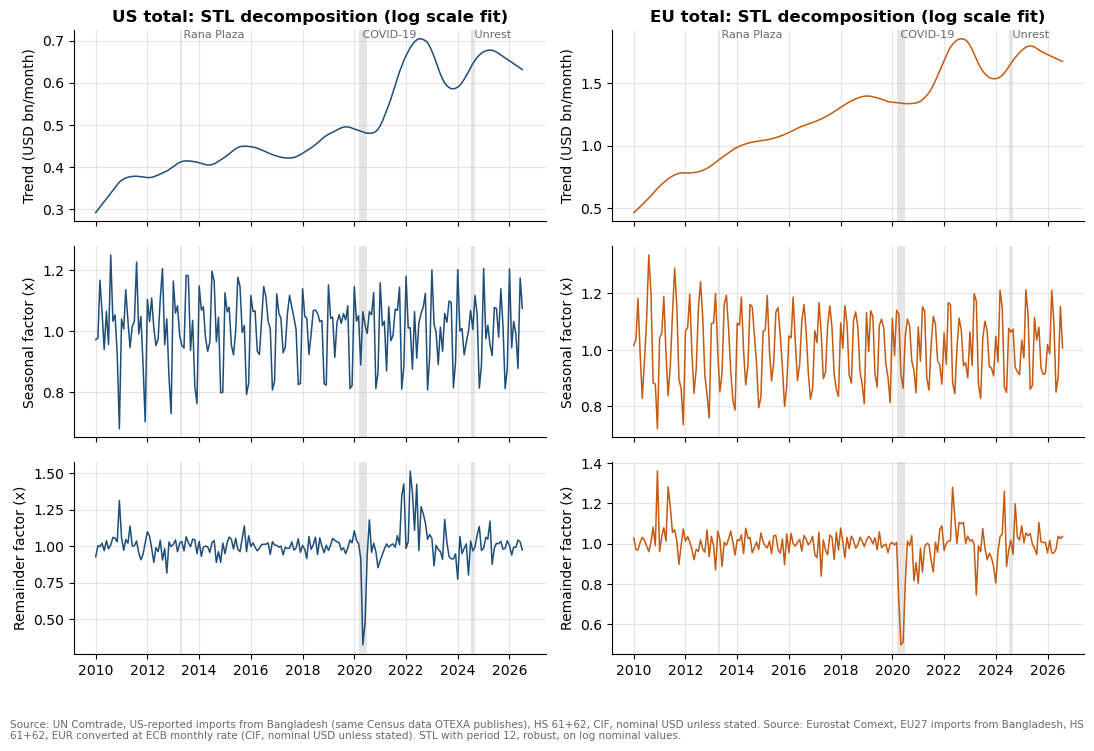

In [3]:
stl = {}
fig, axes = plt.subplots(3, 2, figsize=(11, 7.5), sharex=True)
for j, m in enumerate(['US', 'EU']):
    y = np.log(w[('value_usd', m)].dropna())
    r = STL(y, period=12, robust=True).fit(); stl[m] = r
    for i, (comp, lab) in enumerate([(np.exp(r.trend), 'Trend (USD bn/month)'), (np.exp(r.seasonal), 'Seasonal factor (x)'), (np.exp(r.resid), 'Remainder factor (x)')]):
        ax = axes[i, j]; ax.plot(comp.index, comp, color=COLORS[m], lw=1.1)
        shade_events(ax, label=(i == 0)); ax.set_ylabel(lab)
    axes[0, j].set_title(f'{m} total: STL decomposition (log scale fit)')
save(fig, 'fig02_stl_us_eu', SRC_US + ' ' + SRC_EU + ' STL with period 12, robust, on log nominal values.')
plt.show()

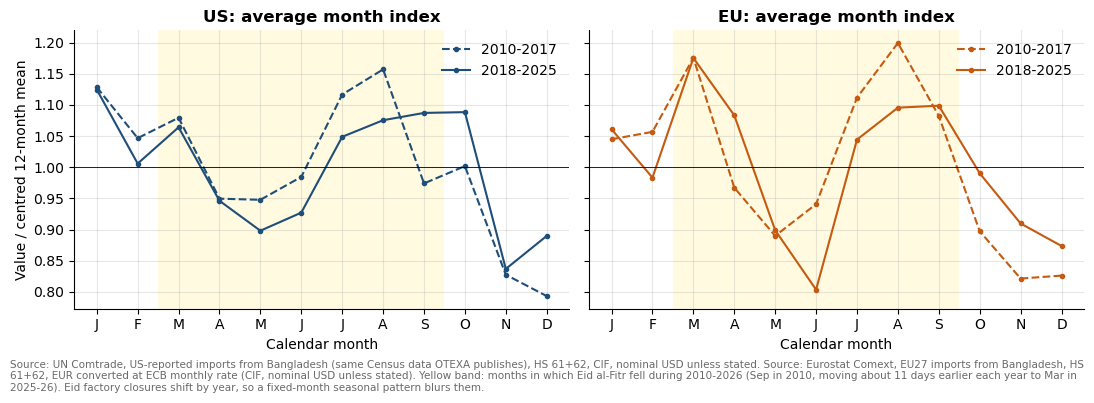

In [4]:
# Average month index: value / 12-month centred mean, averaged by calendar month, two periods
def month_index(s):
    s = s.dropna(); ma = s.rolling(12, center=True).mean().rolling(2).mean().shift(-1)
    idx = (s / ma).dropna()
    return idx
rows = []
for m in ['US', 'EU']:
    idx = month_index(w[('value_usd', m)])
    for per, (a, b) in {'2010-2017': ('2010', '2017'), '2018-2025': ('2018', '2025')}.items():
        x = idx[a:b]; x = x.groupby(x.index.month).mean()
        rows += [dict(market=m, period=per, month=k, index=v) for k, v in x.items()]
season = pd.DataFrame(rows)
season.to_csv(TAB / 'seasonal_month_index.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
mon = ['J','F','M','A','M','J','J','A','S','O','N','D']
for ax, m in zip(axes, ['US', 'EU']):
    for per, ls in [('2010-2017', '--'), ('2018-2025', '-')]:
        s = season[(season.market == m) & (season.period == per)]
        ax.plot(s.month, s['index'], ls, color=COLORS[m], marker='o', ms=3, label=per)
    ax.axhline(1, color='k', lw=0.6); ax.set_xticks(range(1, 13), mon)
    ax.axvspan(2.5, 9.5, color='gold', alpha=0.12, lw=0)
    ax.set_title(f'{m}: average month index'); ax.set_xlabel('Calendar month'); ax.legend()
axes[0].set_ylabel('Value / centred 12-month mean')
save(fig, 'fig03_seasonal_month_index', SRC_US + ' ' + SRC_EU + ' Yellow band: months in which Eid al-Fitr fell during 2010-2026 '
     '(Sep in 2010, moving about 11 days earlier each year to Mar in 2025-26). Eid factory closures shift by year, so a fixed-month seasonal pattern blurs them.')
plt.show()

Eid al-Fitr moves about 11 days earlier each year (September in 2010, March in 2025-26). Factory closures around Eid move with it, so a fixed calendar-month seasonal factor does not capture the holiday well. The forecasting models should test an Eid dummy.

## 3. Year-on-year growth by US product group

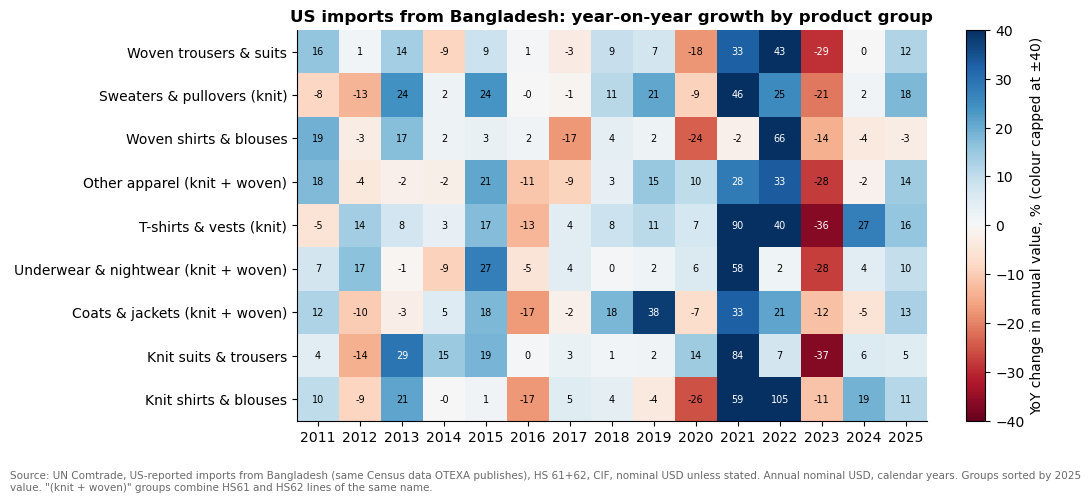

In [5]:
us = d[d.market == 'US'].copy(); us['year'] = us.date.dt.year
ann = us[us.year <= 2025].pivot_table(index='product_group', columns='year', values='value_usd', aggfunc='sum') / 1e6
# Groups found in both chapters (e.g. coats, underwear) are summed over knit HS61 and woven HS62
both = us.groupby('product_group').chapter.nunique().loc[lambda x: x > 1].index
ann = ann.rename(index={g: f'{g} (knit + woven)' for g in both})
yoy = ann.pct_change(axis=1).iloc[:, 1:] * 100
yoy = yoy.loc[ann[2025].sort_values(ascending=False).index]
yoy.round(1).to_csv(TAB / 'us_yoy_by_group.csv')
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(yoy.clip(-40, 40), cmap='RdBu', vmin=-40, vmax=40, aspect='auto')
ax.set_xticks(range(yoy.shape[1]), yoy.columns); ax.set_yticks(range(len(yoy)), yoy.index); ax.grid(False)
for i in range(yoy.shape[0]):
    for j in range(yoy.shape[1]):
        v = yoy.iat[i, j]; ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7, color='white' if abs(v) > 28 else 'black')
fig.colorbar(im, ax=ax, label='YoY change in annual value, % (colour capped at ±40)')
ax.set_title('US imports from Bangladesh: year-on-year growth by product group')
save(fig, 'fig04_us_yoy_heatmap', SRC_US + ' Annual nominal USD, calendar years. Groups sorted by 2025 value. "(knit + woven)" groups combine HS61 and HS62 lines of the same name.')
plt.show()

## 4. US product mix

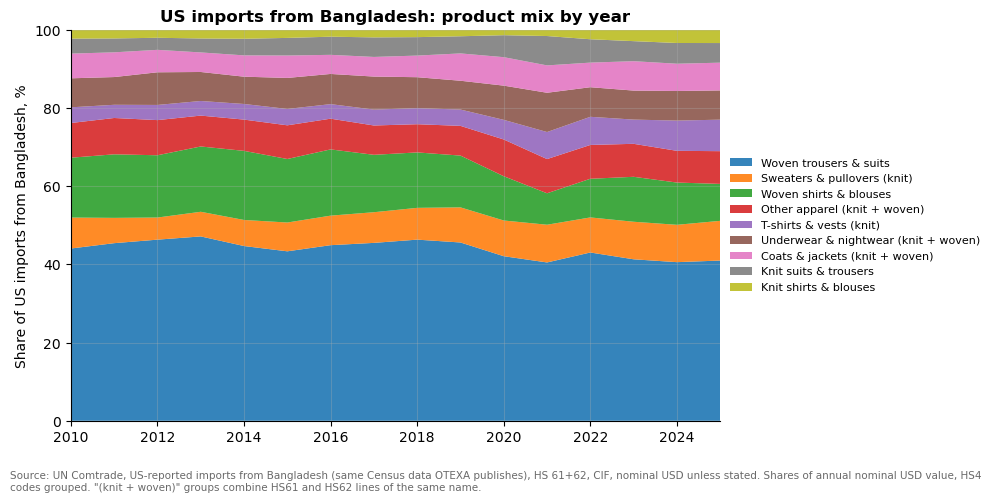

In [6]:
share = ann.div(ann.sum()) * 100
share = share.loc[ann[2025].sort_values(ascending=False).index]
share.round(2).to_csv(TAB / 'us_product_share.csv')
fig, ax = plt.subplots(figsize=(10, 5))
cols = plt.cm.tab10(range(len(share)))
ax.stackplot(share.columns, share.values, labels=share.index, colors=cols, alpha=0.9)
ax.set_xlim(2010, 2025); ax.set_ylim(0, 100); ax.set_ylabel('Share of US imports from Bangladesh, %')
ax.set_title('US imports from Bangladesh: product mix by year')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=8)
save(fig, 'fig05_us_product_mix', SRC_US + ' Shares of annual nominal USD value, HS4 codes grouped. "(knit + woven)" groups combine HS61 and HS62 lines of the same name.')
plt.show()

## 5. Market concentration (mirror data, CIF basis)

Shares come from partner-reported imports, so the denominator is CIF and larger than Bangladesh's FOB exports. The US share here (14-15%) is below the 18-20% seen on EPB figures for that reason.

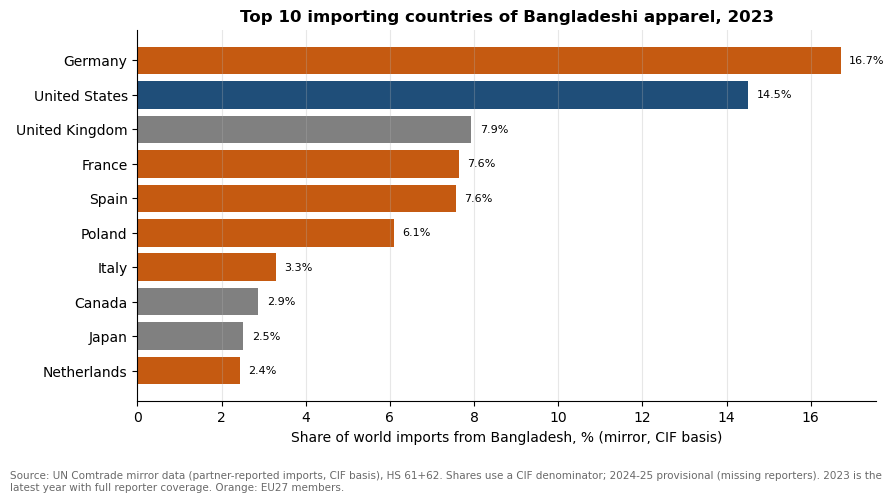

In [7]:
mk = pd.read_csv(ROOT / 'data/processed/rmg_market_annual.csv')
hhi = pd.read_csv(TAB / 'hhi_by_year.csv')
latest = int(hhi[hhi.year_complete].year.max())
y = mk[mk.year == latest].copy()
eu = y[y.eu27_member].value_usd.sum()
bloc = pd.concat([y[~y.eu27_member][['market', 'value_usd']], pd.DataFrame([{'market': 'EU27 (bloc)', 'value_usd': eu}])])
bloc['share'] = bloc.value_usd / y.value_usd.sum() * 100
top = y.nlargest(10, 'value_usd').assign(share=lambda t: t.value_usd / y.value_usd.sum() * 100)
top[['market', 'value_usd', 'share']].to_csv(TAB / f'top10_markets_{latest}.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 5))
t = top.iloc[::-1]
ax.barh(t.market, t.share, color=[COLORS['EU'] if e else COLORS['US'] if m == 'United States' else 'grey' for m, e in zip(t.market, t.eu27_member)])
for i, v in enumerate(t.share): ax.text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=8)
ax.set_xlabel('Share of world imports from Bangladesh, % (mirror, CIF basis)')
ax.set_title(f'Top 10 importing countries of Bangladeshi apparel, {latest}'); ax.grid(axis='y', visible=False)
save(fig, 'fig06_top10_markets', SRC_MIRROR + f' {latest} is the latest year with full reporter coverage. Orange: EU27 members.')
plt.show()

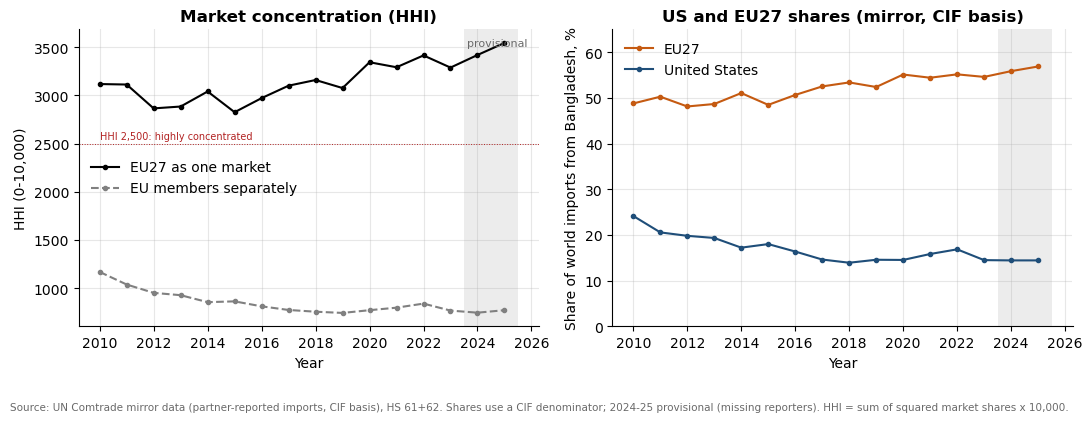

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
h = hhi.set_index('year')
ax = axes[0]
ax.plot(h.index, h.hhi_eu_as_bloc, color='k', marker='o', ms=3, label='EU27 as one market')
ax.plot(h.index, h.hhi_countries, color='grey', marker='o', ms=3, ls='--', label='EU members separately')
ax.axvspan(2023.5, 2025.5, color='grey', alpha=0.15, lw=0); ax.text(2023.6, 0.97, 'provisional', transform=ax.get_xaxis_transform(), fontsize=8, va='top', color='dimgray')
ax.axhline(2500, color='firebrick', lw=0.7, ls=':'); ax.text(2010, 2550, 'HHI 2,500: highly concentrated', fontsize=7, color='firebrick')
ax.set_ylabel('HHI (0-10,000)'); ax.set_title('Market concentration (HHI)'); ax.legend(loc='center left')
ax = axes[1]
ax.plot(h.index, h.eu27_share * 100, color=COLORS['EU'], marker='o', ms=3, label='EU27')
ax.plot(h.index, h.us_share * 100, color=COLORS['US'], marker='o', ms=3, label='United States')
ax.axvspan(2023.5, 2025.5, color='grey', alpha=0.15, lw=0)
ax.set_ylim(0, 65); ax.set_ylabel('Share of world imports from Bangladesh, %'); ax.set_title('US and EU27 shares (mirror, CIF basis)'); ax.legend()
for a in axes: a.set_xlabel('Year')
save(fig, 'fig07_hhi_and_shares', SRC_MIRROR + ' HHI = sum of squared market shares x 10,000.')
plt.show()

## Key facts

Each number below is saved with its method in `outputs/tables/key_facts.csv`.

In [9]:
A = d.assign(year=d.date.dt.year).groupby(['market', 'year']).value_usd.sum() / 1e9
facts = []
def add(name, value, unit, how): facts.append(dict(fact=name, value=round(value, 4), unit=unit, method=how))
for m in ['US', 'EU']:
    add(f'{m} CAGR 2010-2025 (nominal)', cagr(A[m, 2010], A[m, 2025], 15) * 100, '%/yr',
        f'(annual {m} imports 2025 / 2010)^(1/15) - 1; calendar-year sums of value_usd, rmg_long.csv. 2010 = {A[m,2010]:.2f}bn, 2025 = {A[m,2025]:.2f}bn')
    pk = A[m].loc[2010:2025].idxmax()
    add(f'{m} peak year (nominal, 2010-2025)', pk, 'year', f'year with highest annual value_usd sum; {A[m, pk]:.2f}bn')
    add(f'{m} 2025 vs 2022 change (nominal)', (A[m, 2025] / A[m, 2022] - 1) * 100, '%', f'annual sum 2025 / 2022 - 1; {A[m,2022]:.2f}bn to {A[m,2025]:.2f}bn')
R = d.assign(year=d.date.dt.year).groupby(['market', 'year']).value_usd_real2025.sum() / 1e9
add('US CAGR 2010-2025 (real 2025 USD)', cagr(R['US', 2010], R['US', 2025], 15) * 100, '%/yr', 'same as nominal CAGR, using value_usd_real2025 (CPI-U deflated)')
ts = share.loc[['T-shirts & vests (knit)', 'Sweaters & pullovers (knit)'], 2025].sum()
add('T-shirts + sweaters share of US imports, 2025', ts, '%', 'sum of the two product groups / all US groups, 2025 annual nominal value')
add('HHI (EU as bloc) change 2010-2023', h.loc[2023, 'hhi_eu_as_bloc'] - h.loc[2010, 'hhi_eu_as_bloc'], 'HHI points',
    f"hhi_by_year.csv, 2023 ({h.loc[2023,'hhi_eu_as_bloc']:.0f}) minus 2010 ({h.loc[2010,'hhi_eu_as_bloc']:.0f}); 2023 = last complete mirror year")
add(f'EU27 share of world imports from BD, {latest}', h.loc[latest, 'eu27_share'] * 100, '%', 'mirror data, CIF basis, hhi_by_year.csv')
kf = pd.DataFrame(facts); kf.to_csv(TAB / 'key_facts.csv', index=False)
pd.set_option('display.max_colwidth', 200); kf

,fact,value,unit,method
0,US CAGR 2010-2025 (nominal),4.7988,%/yr,"(annual US imports 2025 / 2010)^(1/15) - 1; calendar-year sums of value_usd, rmg_long.csv. 2010 = 4.06bn, 2025 = 8.21bn"
1,"US peak year (nominal, 2010-2025)",2022.0000,year,year with highest annual value_usd sum; 9.83bn
2,US 2025 vs 2022 change (nominal),-16.4639,%,annual sum 2025 / 2022 - 1; 9.83bn to 8.21bn
3,EU CAGR 2010-2025 (nominal),7.9810,%/yr,"(annual EU imports 2025 / 2010)^(1/15) - 1; calendar-year sums of value_usd, rmg_long.csv. 2010 = 6.92bn, 2025 = 21.90bn"
4,"EU peak year (nominal, 2010-2025)",2022.0000,year,year with highest annual value_usd sum; 23.00bn
5,EU 2025 vs 2022 change (nominal),-4.7835,%,annual sum 2025 / 2022 - 1; 23.00bn to 21.90bn
6,US CAGR 2010-2025 (real 2025 USD),2.1112,%/yr,"same as nominal CAGR, using value_usd_real2025 (CPI-U deflated)"
7,"T-shirts + sweaters share of US imports, 2025",18.2170,%,"sum of the two product groups / all US groups, 2025 annual nominal value"
8,HHI (EU as bloc) change 2010-2023,170.6598,HHI points,"hhi_by_year.csv, 2023 (3288) minus 2010 (3117); 2023 = last complete mirror year"
9,"EU27 share of world imports from BD, 2023",54.6100,%,"mirror data, CIF basis, hhi_by_year.csv"
